# NBA Game Outcome/Score Prediction - Data Exploration

## Project Objective
The Objective of this project is to use historical NBA game statistics to predict whether the home team will win a game.

We will also investigate the feasibility of predicting final scores and point differentials using regression models.

## Dataset

Source: Wyatt walsh NBA Database (Kaggle)
https://www.kaggle.com/datasets/wyattowalsh/basketball



### Import libraries

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb

### Load data

In [30]:
df = pd.read_csv("../data/game.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


### Display first and last rows

In [31]:
display(df.head())

,season_id,team_id_home,team_abbreviation_home,team_name_home,game_id,game_date,matchup_home,wl_home,min,fgm_home,...,reb_away,ast_away,stl_away,blk_away,tov_away,pf_away,pts_away,plus_minus_away,video_available_away,season_type
0,21946,1610610035,HUS,Toronto Huskies,24600001,1946-11-01 00:00:00,HUS vs. NYK,L,0,25.0,...,NaN,NaN,NaN,NaN,NaN,NaN,68.0,2,0,Regular Season
1,21946,1610610034,BOM,St. Louis Bombers,24600003,1946-11-02 00:00:00,BOM vs. PIT,W,0,20.0,...,NaN,NaN,NaN,NaN,NaN,25.0,51.0,-5,0,Regular Season
2,21946,1610610032,PRO,Providence Steamrollers,24600002,1946-11-02 00:00:00,PRO vs. BOS,W,0,21.0,...,NaN,NaN,NaN,NaN,NaN,NaN,53.0,-6,0,Regular Season
3,21946,1610610025,CHS,Chicago Stags,24600004,1946-11-02 00:00:00,CHS vs. NYK,W,0,21.0,...,NaN,NaN,NaN,NaN,NaN,22.0,47.0,-16,0,Regular Season
4,21946,1610610028,DEF,Detroit Falcons,24600005,1946-11-02 00:00:00,DEF vs. WAS,L,0,10.0,...,NaN,NaN,NaN,NaN,NaN,NaN,50.0,17,0,Regular Season


In [32]:
display(df.tail())

,season_id,team_id_home,team_abbreviation_home,team_name_home,game_id,game_date,matchup_home,wl_home,min,fgm_home,...,reb_away,ast_away,stl_away,blk_away,tov_away,pf_away,pts_away,plus_minus_away,video_available_away,season_type
65693,42022,1610612748,MIA,Miami Heat,42200403,2023-06-07 00:00:00,MIA vs. DEN,L,240,34.0,...,58.0,28.0,3.0,5.0,14.0,18.0,109.0,15,1,Playoffs
65694,42022,1610612748,MIA,Miami Heat,42200404,2023-06-09 00:00:00,MIA vs. DEN,L,240,35.0,...,34.0,26.0,11.0,7.0,8.0,18.0,108.0,13,1,Playoffs
65695,42022,1610612743,DEN,Denver Nuggets,42200405,2023-06-12 00:00:00,DEN vs. MIA,W,240,38.0,...,44.0,18.0,9.0,7.0,8.0,21.0,89.0,-5,1,Playoffs
65696,32022,1610616834,LBN,Team LeBron,32200001,2023-02-19 00:00:00,LBN vs. GNS,L,221,79.0,...,46.0,43.0,8.0,1.0,12.0,2.0,184.0,9,1,All-Star
65697,32022,1610616834,LBN,Team LeBron,32200001,2023-02-19 00:00:00,LBN vs. GNS,L,221,79.0,...,46.0,43.0,8.0,1.0,12.0,2.0,184.0,9,1,All Star


### Dataset Dimensions 

In [33]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 65698
Number of columns: 55


### Column names and data types

In [34]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 65698 entries, 0 to 65697
Data columns (total 55 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   season_id               65698 non-null  int64  
 1   team_id_home            65698 non-null  int64  
 2   team_abbreviation_home  65698 non-null  str    
 3   team_name_home          65698 non-null  str    
 4   game_id                 65698 non-null  int64  
 5   game_date               65698 non-null  str    
 6   matchup_home            65698 non-null  str    
 7   wl_home                 65696 non-null  str    
 8   min                     65698 non-null  int64  
 9   fgm_home                65685 non-null  float64
 10  fga_home                50251 non-null  float64
 11  fg_pct_home             50208 non-null  float64
 12  fg3m_home               52480 non-null  float64
 13  fg3a_home               47015 non-null  float64
 14  fg3_pct_home            46624 non-null  float64
 

### Summary Statistics

In [35]:
display(df.describe())

,season_id,team_id_home,game_id,min,fgm_home,fga_home,fg_pct_home,fg3m_home,fg3a_home,fg3_pct_home,...,dreb_away,reb_away,ast_away,stl_away,blk_away,tov_away,pf_away,pts_away,plus_minus_away,video_available_away
count,65698.000000,6.569800e+04,6.569800e+04,65698.000000,65685.000000,50251.000000,50208.000000,52480.000000,47015.000000,46624.000000,...,46700.000000,49973.000000,49897.000000,46849.000000,47073.000000,47013.000000,62847.000000,65698.000000,65698.000000,65698.000000
mean,22949.338747,1.609926e+09,2.584747e+07,221.003486,39.672269,83.992796,0.467321,5.735099,17.741146,0.346136,...,30.238073,42.119645,22.135419,7.854148,4.681537,15.199860,23.097284,100.991567,-3.627569,0.201330
std,5000.305500,3.324313e+07,6.303760e+06,67.903521,6.770802,9.164445,0.059423,4.537337,10.545810,0.151234,...,5.588675,6.867396,5.380805,3.031766,2.500820,4.299798,5.227208,14.418755,13.091395,0.400997
min,12005.000000,4.500000e+01,1.050000e+07,0.000000,4.000000,0.000000,0.140000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,19.000000,-73.000000,0.000000
25%,21981.000000,1.610613e+09,2.130053e+07,240.000000,35.000000,78.000000,0.427000,2.000000,10.000000,0.261000,...,26.000000,37.000000,18.000000,6.000000,3.000000,12.000000,20.000000,92.000000,-12.000000,0.000000
50%,21997.000000,1.610613e+09,2.630007e+07,240.000000,40.000000,84.000000,0.467000,5.000000,16.000000,0.348000,...,30.000000,42.000000,22.000000,8.000000,4.000000,15.000000,23.000000,101.000000,-4.000000,0.000000
75%,22011.000000,1.610613e+09,2.880069e+07,240.000000,44.000000,89.000000,0.506000,9.000000,24.000000,0.429750,...,34.000000,47.000000,26.000000,10.000000,6.000000,18.000000,26.000000,110.000000,5.000000,0.000000
max,42022.000000,1.610617e+09,4.980009e+07,365.000000,84.000000,240.000000,0.697000,28.000000,77.000000,1.000000,...,60.000000,90.000000,89.000000,27.000000,19.000000,40.000000,115.000000,196.000000,68.000000,1.000000


### Missing values

In [36]:
missing = df.isnull().sum()
print("Missing count:\n", missing)

Missing count:
 season_id                     0
team_id_home                  0
team_abbreviation_home        0
team_name_home                0
game_id                       0
game_date                     0
matchup_home                  0
wl_home                       2
min                           0
fgm_home                     13
fga_home                  15447
fg_pct_home               15490
fg3m_home                 13218
fg3a_home                 18683
fg3_pct_home              19074
ftm_home                     16
fta_home                   3004
ft_pct_home                3009
oreb_home                 18936
dreb_home                 18999
reb_home                  15729
ast_home                  15805
stl_home                  18849
blk_home                  18626
tov_home                  18684
pf_home                    2856
pts_home                      0
plus_minus_home               0
video_available_home          0
team_id_away                  0
team_abbreviation_away  

In [37]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


## Investigate Season Coverage

We will examine the historical date range of the dataset to determine which NBA seasons are most appropriate for our machine learning models.

In [38]:
df["game_date"] = pd.to_datetime(df["game_date"])

print("Earliest game:", df["game_date"].min())
print("Latest game:", df["game_date"].max())

Earliest game: 1946-11-01 00:00:00
Latest game: 2023-06-12 00:00:00


## Season Type
For our initial model, we will focus on regular-season games because they provice more consistent obervations and avoid mixing in playoff-specific conditions.

This is to check the counts of each

In [39]:
# Check Season Types
print(df["season_type"].value_counts())

season_type
Regular Season    60192
Playoffs           3842
Pre Season         1536
All Star             65
All-Star             63
Name: count, dtype: int64


## Check modern games

In [40]:
modern_df = df[(df["game_date"] >= "2010-10-01") & (df["season_type"] == "Regular Season")].copy()

print("Number of Original games:", len(df))
print("Number of modern regular-season games:", len(modern_df))

Number of Original games: 65698
Number of modern regular-season games: 14199


In [41]:
## Compare missing values in modern games vs. all games

missing_modern = modern_df.isnull().sum()
print(missing_modern[missing_modern > 0])

Series([], dtype: int64)


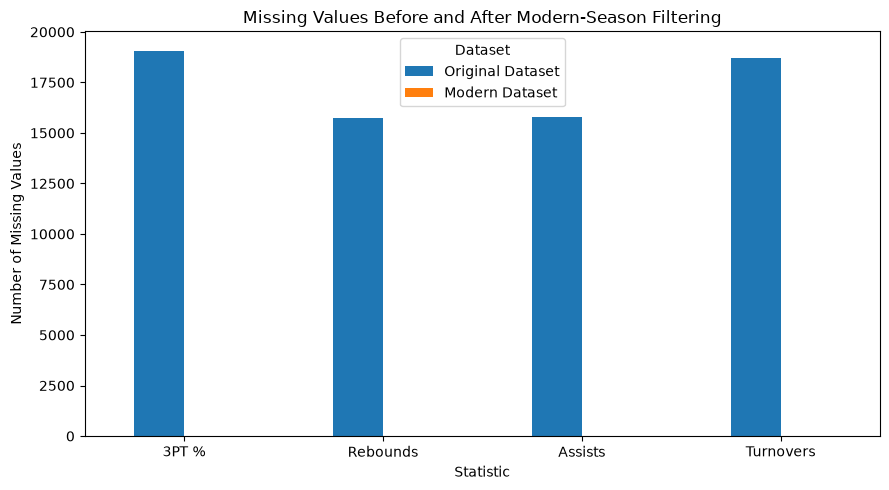

In [42]:
missing_columns = [
    "fg3_pct_home",
    "reb_home",
    "ast_home",
    "tov_home"
]

original_missing = df[missing_columns].isnull().sum()
modern_missing = modern_df[missing_columns].isnull().sum()

missing_comparison = pd.DataFrame({
    "Original Dataset": original_missing,
    "Modern Dataset": modern_missing
})

missing_comparison.index = [
    "3PT %",
    "Rebounds",
    "Assists",
    "Turnovers"
]

missing_comparison.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Missing Values Before and After Modern-Season Filtering")
plt.xlabel("Statistic")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=0)
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()

Based on the filtering of modern NBA seasons, it handles all of the missing values, implying that they were all due to missing statistical data from older seasons.

# Analyzing target variable and class imbalance

**Do home teams win significantly more often than away teams in our dataset and how might that affect model evaluation?**

We will examine the distribution of home-team wins and losses to determine of home-team wins and losses to determine whether our classification target is imbalanced

In [43]:
modern_df["home_win"] = modern_df["wl_home"].map({"W":1, "L":0})

print(modern_df["home_win"].value_counts())

home_win
1    8181
0    6018
Name: count, dtype: int64


In [44]:
class_percentages = (modern_df["home_win"]
    .value_counts(normalize=True)
    .sort_index() * 100
    )
print(class_percentages.round(2))

home_win
0    42.38
1    57.62
Name: proportion, dtype: float64


## Visualize imbalance

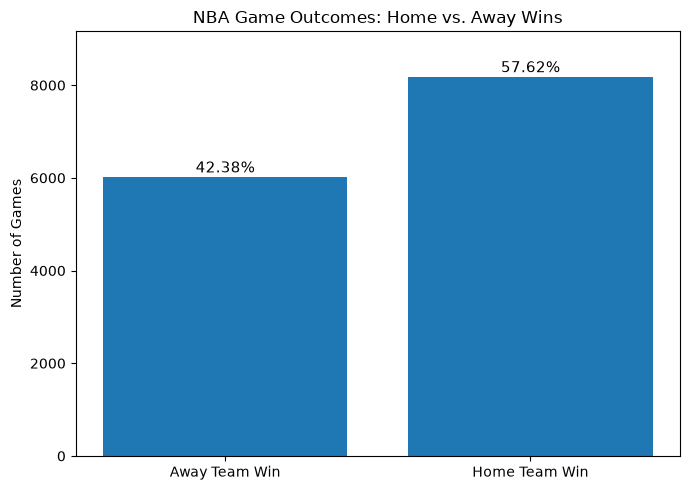

In [45]:
win_counts = modern_df["home_win"].value_counts().sort_index()

labels = ["Away Team Win", "Home Team Win"]
percentages = win_counts / win_counts.sum() * 100

plt.figure(figsize=(7, 5))

bars = plt.bar(
    labels,
    win_counts.values
)

for bar, percentage in zip(bars, percentages):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 100,
        f"{percentage:.2f}%",
        ha="center",
        fontsize=11
    )

plt.title("NBA Game Outcomes: Home vs. Away Wins")
plt.ylabel("Number of Games")
plt.ylim(0, max(win_counts) * 1.12)

plt.tight_layout()
plt.show()

# Analyze home and away scoring distributions

We will now analyze the distributions of important NBA game statistics to understand their averages, variability, and potential outliers.

## Home and Away Team Scoring

We will now compare points scored by home and away teams to investigate whether there are differences in scoring perfomance 

In [46]:
scoring_stats = modern_df[
    ["pts_home", "pts_away"]].agg(["mean", "median", "std", "min", "max"])

display(scoring_stats.round(2))

,pts_home,pts_away
mean,107.23,104.80
median,107.00,105.00
std,13.25,13.42
min,59.00,56.00
max,175.00,176.00


## Visualize Home and Away Team Scoring

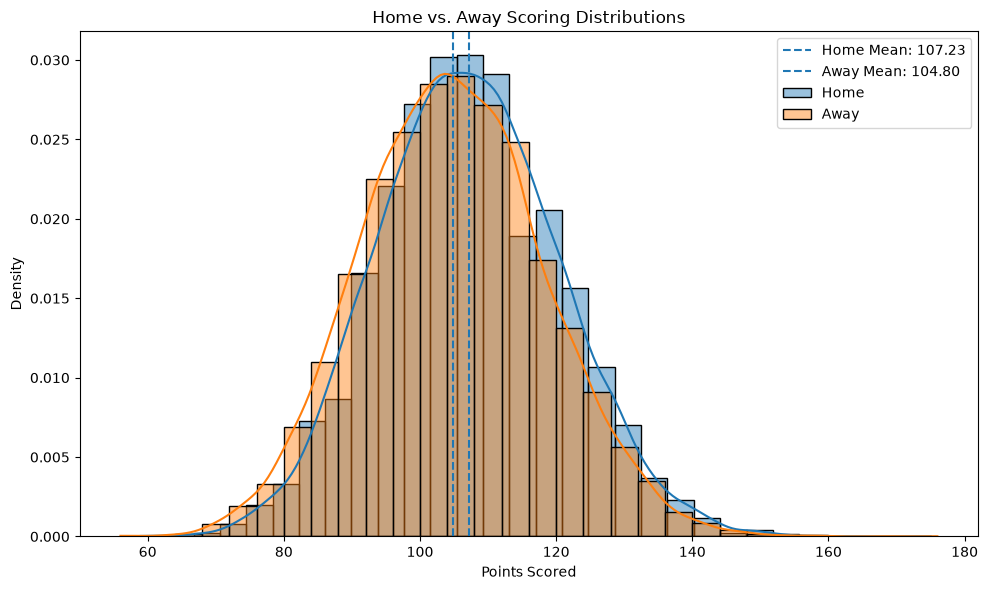

In [47]:
plt.figure(figsize=(10, 6))

sb.histplot(
    modern_df["pts_home"],
    bins=30,
    stat="density",
    alpha=0.45,
    label="Home",
    kde=True
)

sb.histplot(
    modern_df["pts_away"],
    bins=30,
    stat="density",
    alpha=0.45,
    label="Away",
    kde=True
)

home_mean = modern_df["pts_home"].mean()
away_mean = modern_df["pts_away"].mean()

plt.axvline(
    home_mean,
    linestyle="--",
    label=f"Home Mean: {home_mean:.2f}"
)

plt.axvline(
    away_mean,
    linestyle="--",
    label=f"Away Mean: {away_mean:.2f}"
)

plt.title("Home vs. Away Scoring Distributions")
plt.xlabel("Points Scored")
plt.ylabel("Density")
plt.legend()

plt.tight_layout()
plt.show()

# Outlier Analysis

We will use boxplots to examine the distributions of home and away team scores and identify potential outliers.

This analysis will help us determine whether unusually high or low scoring games could affect our regression models

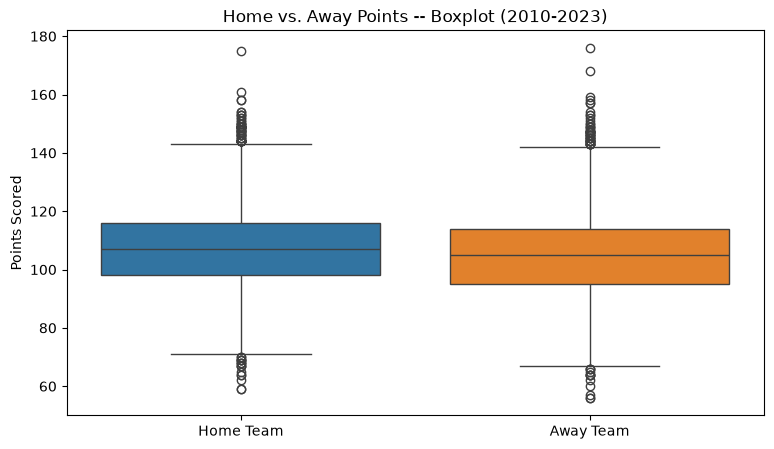

In [48]:
plt.figure(figsize=(9,5))

sb.boxplot(data=modern_df[["pts_home", "pts_away"]])

plt.title("Home vs. Away Points -- Boxplot (2010-2023)")
plt.ylabel("Points Scored")
plt.xticks([0,1], ["Home Team", "Away Team"])

plt.show()

# IQR method for outliers

In [49]:
Q1 = modern_df["pts_home"].quantile(0.25)
Q3 = modern_df["pts_home"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

home_outliers = modern_df[
    (modern_df["pts_home"] < lower_bound) |
    (modern_df["pts_home"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of home scoring outliers:", len(home_outliers))

print(
    "Percentage of games flagged:",
    round(len(home_outliers) / len(modern_df) * 100, 2),
    "%"
)

Q1: 98.0
Q3: 116.0
IQR: 18.0
Lower bound: 71.0
Upper bound: 143.0
Number of home scoring outliers: 77
Percentage of games flagged: 0.54 %


## Feature Relationships and Correlation Analysis

We will investigate relationships between NBA game statistics to identify potentially useful features for our machine learning models.

We will also examine whether some statistics are highly correlated with one another, which may indicate redundant information

In [50]:
# selecting features to investigate
correlation_features = [
    "pts_home",
    "fg_pct_home",
    "fg3_pct_home",
    "ft_pct_home",
    "reb_home",
    "ast_home",
    "tov_home",
    "home_win"
]

## Visualize using correlation matrix

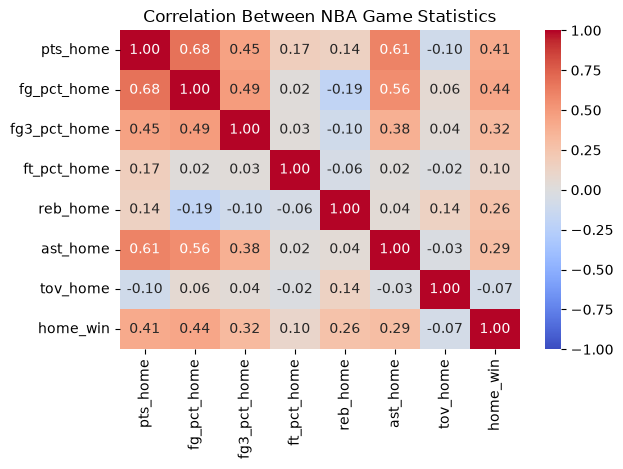

In [51]:
corr_matrix = modern_df[correlation_features].corr()
sb.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Between NBA Game Statistics")
plt.tight_layout()
plt.show()

Shooting efficiency and scoring are strongly associated with game outcomes, making their historical averages useful candidates for our prediction models.